# Historical alert escalation — legitimate, reproducible modeling

Predict a continuous escalation probability for each test alert. **Metric: ROC-AUC.**

The final recipe is an equal-weight LightGBM/CatBoost blend. This notebook rebuilds features from the original competition files, runs the useful comparative experiments, audits a frozen recipe with inner early stopping, refits on all training alerts, and validates the final CSV. The full exploratory history is in `EXPERIMENTS.md`.

**Leakage rule:** interpret the date-only alert as midnight; retain transactions at or before that timestamp. Exclude later transactions and their counts. Never use IDs, sample probabilities, or unavailable labels as predictors.

## 1. Imports and configuration

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '8'
os.environ['OPENBLAS_NUM_THREADS'] = '8'
from pathlib import Path
import sys, json, gc, contextlib, io
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'solution' / 'data.py').exists())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
SEED = 20260927
np.random.seed(SEED)
REBUILD_FEATURES = True
RETRAIN_CORE_EXPERIMENTS = True
TEAM_ID = 'SUBMIT_READY'  # Change only the filename identifier when your team ID is known.

from solution.data import load_data, inspect_data, ARTIFACTS
from solution.features import prepare_features
from solution.enhanced import prepare_enhanced
from solution.modeling import CONFIGS, run_experiment, update_results, make_splits
from solution.eda import generate_eda
from solution.diagnostics import validation_diagnostics
from solution.finalize import assess_blends, finalize, validate_submission
from solution.report import generate_report
print('Project:', ROOT)
print('Python:', sys.version)

Project: D:\Data science\hakathon\wiut_task
Python: 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]


## 2. Data loading
The sample CSV is used only for IDs and ordering. Its probability values are never loaded.

In [2]:
train, test, train_transactions, test_transactions, sample = load_data()
display(pd.DataFrame({'table': ['train signals', 'test signals', 'train transactions', 'test transactions'],
                      'rows': [len(train), len(test), len(train_transactions), len(test_transactions)],
                      'columns': [train.shape[1], test.shape[1], train_transactions.shape[1], test_transactions.shape[1]]}))
display(train.head())
display(train_transactions.head())

,table,rows,columns
0,train signals,14000,3
1,test signals,6000,2
2,train transactions,6987663,5
3,test transactions,3027575,5


,signal_id,signal_sanasi,eskalatsiya
0,SG_000002,2026-08-02,0
1,SG_000003,2025-12-15,0
2,SG_000004,2026-02-13,0
3,SG_000005,2026-02-05,0
4,SG_000006,2025-04-18,0


,signal_id,tranzaksiya_vaqti,kirim_chiqim,tranzaksiya_turi,miqdor_indeksi
0,SG_016527,2024-07-06 08:47:18,chiqim,bank_otkazmasi,0.236245
1,SG_016527,2024-07-07 02:13:02,chiqim,bank_otkazmasi,1.130377
2,SG_016527,2024-07-08 11:15:12,kirim,karta,0.466360
3,SG_016527,2024-07-08 15:58:21,kirim,karta,-0.591761
4,SG_016527,2024-07-09 02:33:17,kirim,bank_otkazmasi,-1.108945


## 3. Data validation and historical cutoff
The complete audit records shapes, dtypes, missing values, duplicates, unique IDs, category frequencies, date ranges, amount tails, transactions per signal, and cutoff eligibility. The raw files are fingerprinted for later integrity checks.

In [3]:
del train_transactions, test_transactions
gc.collect()
with contextlib.redirect_stdout(io.StringIO()):
    audit = inspect_data()
display(pd.DataFrame({split: {
    'alerts': d['unique_signals'], 'transactions': d['transaction_shape'][0],
    'duplicate alerts': d['duplicate_signals'], 'duplicate transactions': d['duplicate_transaction_rows'],
    'missing transaction values': sum(d['transaction_missing'].values()),
    'no historical transactions': d['signals_without_historical_transactions'],
    'before alert': d['transactions_before_timestamp'], 'at cutoff': d['transactions_at_timestamp'],
    'after cutoff (excluded)': d['transactions_after_timestamp'],
    'median transactions': d['transactions_per_signal']['50%']
} for split, d in audit['splits'].items()}))
print('Training target rate:', audit['target_rate'])
print('Policy:', audit['leakage_policy'])
display(pd.DataFrame(audit['monthly_target']))

,train,test
alerts,14000.0,6000.0
transactions,6987663.0,3027575.0
duplicate alerts,0.0,0.0
duplicate transactions,0.0,0.0
missing transaction values,0.0,0.0
no historical transactions,0.0,0.0
before alert,6983729.0,3026119.0
at cutoff,3094.0,1405.0
after cutoff (excluded),840.0,51.0
median transactions,461.0,460.5


Training target rate: 0.1717857142857143
Policy: Only transactions timestamped at or before alert midnight. Excluded rows and their counts never enter features. signal_id is only a join key. No target encodings or external data.


,month,size,mean,sum
0,2025-01,505,0.170297,86
1,2025-02,517,0.185687,96
2,2025-03,505,0.176238,89
3,2025-04,470,0.200000,94
4,2025-05,466,0.165236,77
5,2025-06,497,0.142857,71
6,2025-07,746,0.163539,122
7,2025-08,735,0.170068,125
8,2025-09,696,0.139368,97
9,2025-10,856,0.171729,147


**Decision:** exclude 840 training and 51 test transactions after alert midnight. All alerts retain history. Dates span 2025–2026 in both splits; the synthetic calendar is not interpreted relative to the computer's current date. Exactly-at-cutoff transactions remain eligible. Standardized amount indices can be negative and are never described as currency.

## 4. Feature engineering
Feature engineering is target-free and local to each alert. The same functions process both splits. Recent and older comparison windows are disjoint; all divisions are stabilized. Missing category histories remain missing for amount summaries and zero for counts.

In [4]:
base_train, base_test, base_groups = prepare_features(force=REBUILD_FEATURES)
X, X_test, groups = prepare_enhanced(force=REBUILD_FEATURES)
assert X.index.tolist() == train.signal_id.tolist()
assert X_test.index.tolist() == test.signal_id.tolist()
assert X.columns.tolist() == X_test.columns.tolist()
assert 'signal_id' not in X and 'eskalatsiya' not in X
print('Broad features:', base_train.shape, 'Refined features:', X.shape)
display(pd.Series(groups).value_counts().rename('feature count'))
del base_train, base_test
gc.collect()

Building training features


Building test features


Features complete: (14000, 840), (6000, 840)


Building type contrasts and microtime features


Enhanced features: (14000, 1065)


Broad features: (14000, 840) Refined features: (14000, 1065)


types        280
contrasts    195
recent       174
change       124
direction     98
sequence      57
diversity     56
baseline      35
microtime     30
calendar      16
Name: feature count, dtype: int64

31

The 840 initial candidates cover activity, amount distributions, 1/2/3/7/14/30/60/90-day windows, direction/type interactions, changes from older history, burstiness, calendar, and sequence information. The 1,065-feature refinement adds within-alert type contrasts, direction differences within each type, volatility ratios, quantiles, and short timestamp windows. Ablations decide what survives; generating a feature does not imply that it helps.

## 5. EDA
All public-site outputs are aggregate tables. The plots below distinguish alert-weighted summaries from transaction-weighted compositions.

EDA exported to D:\Data science\hakathon\wiut_task\eda_site\data and D:\Data science\hakathon\wiut_task\eda_site\plots


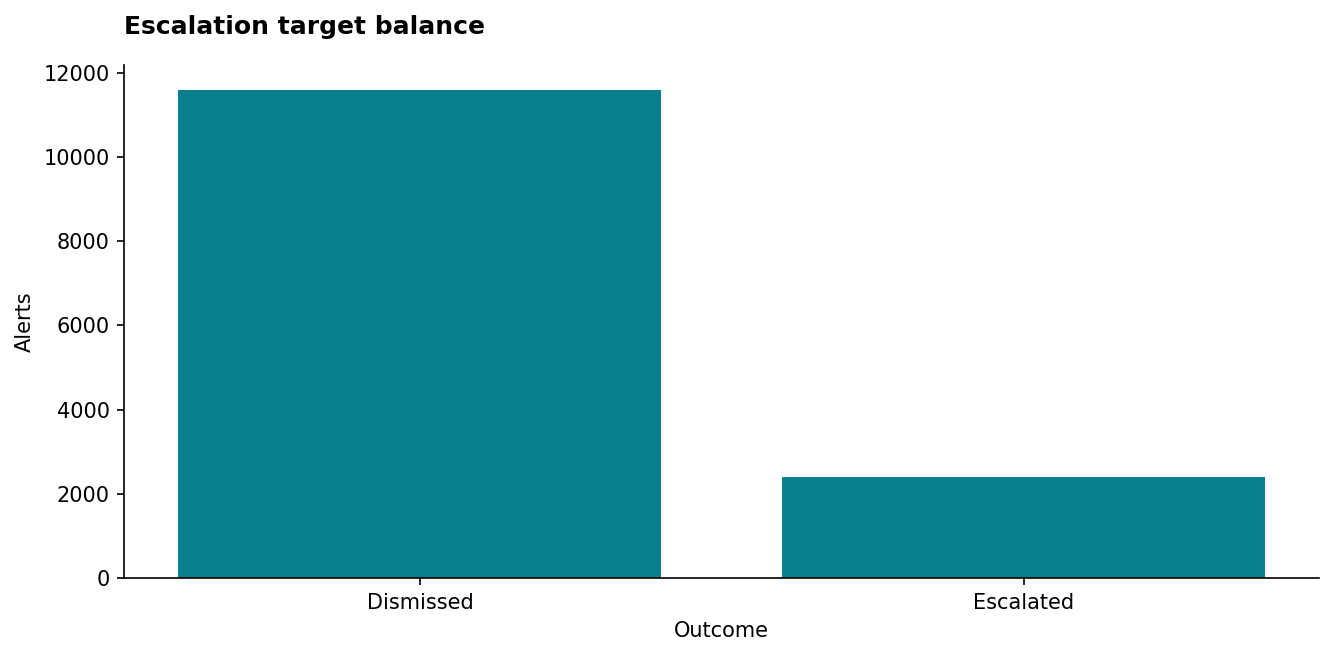

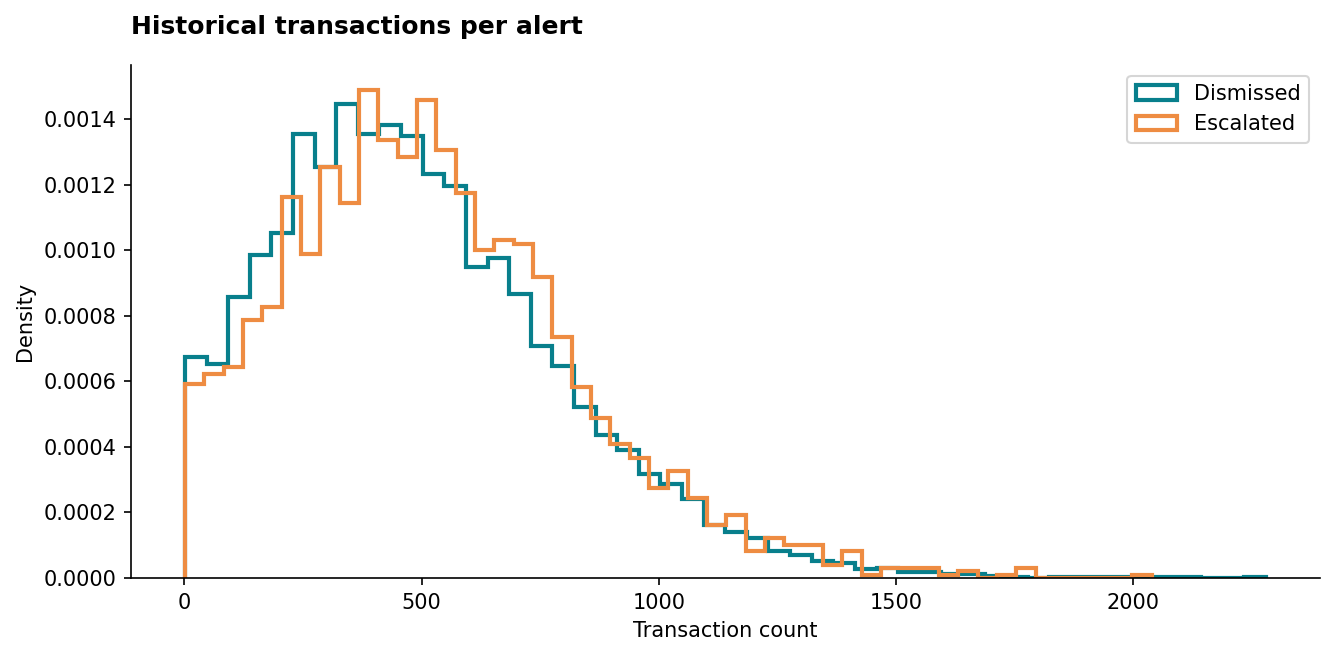

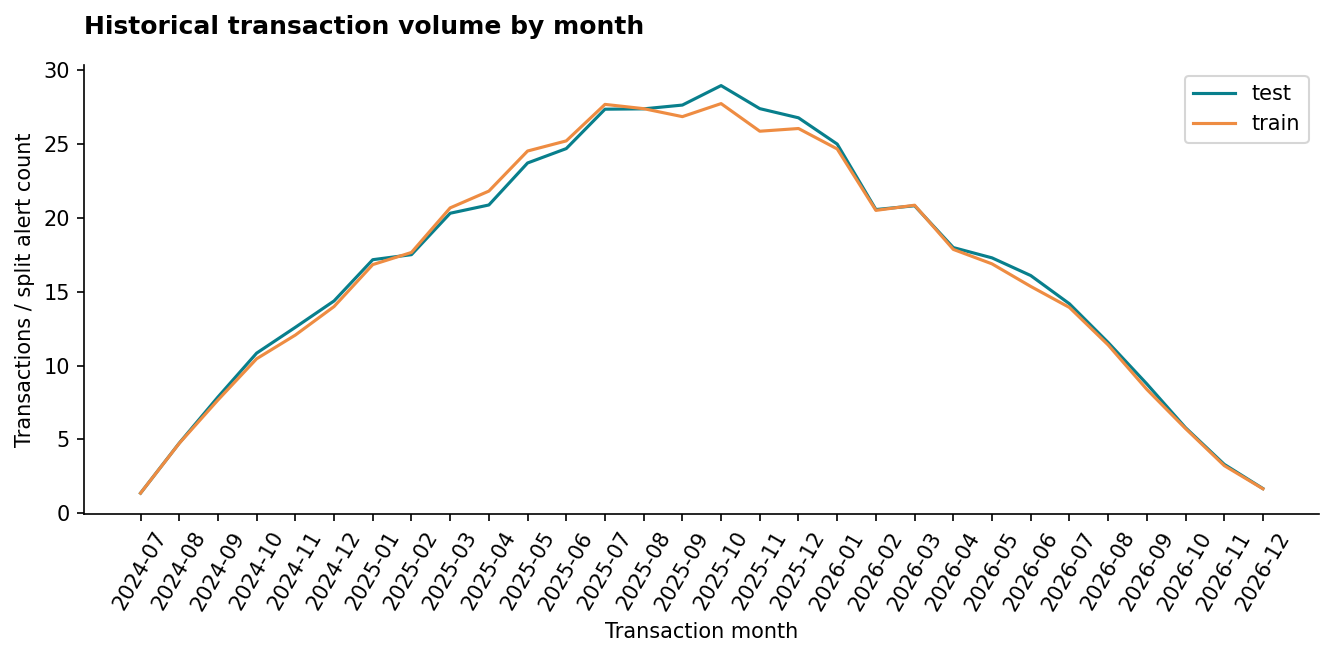

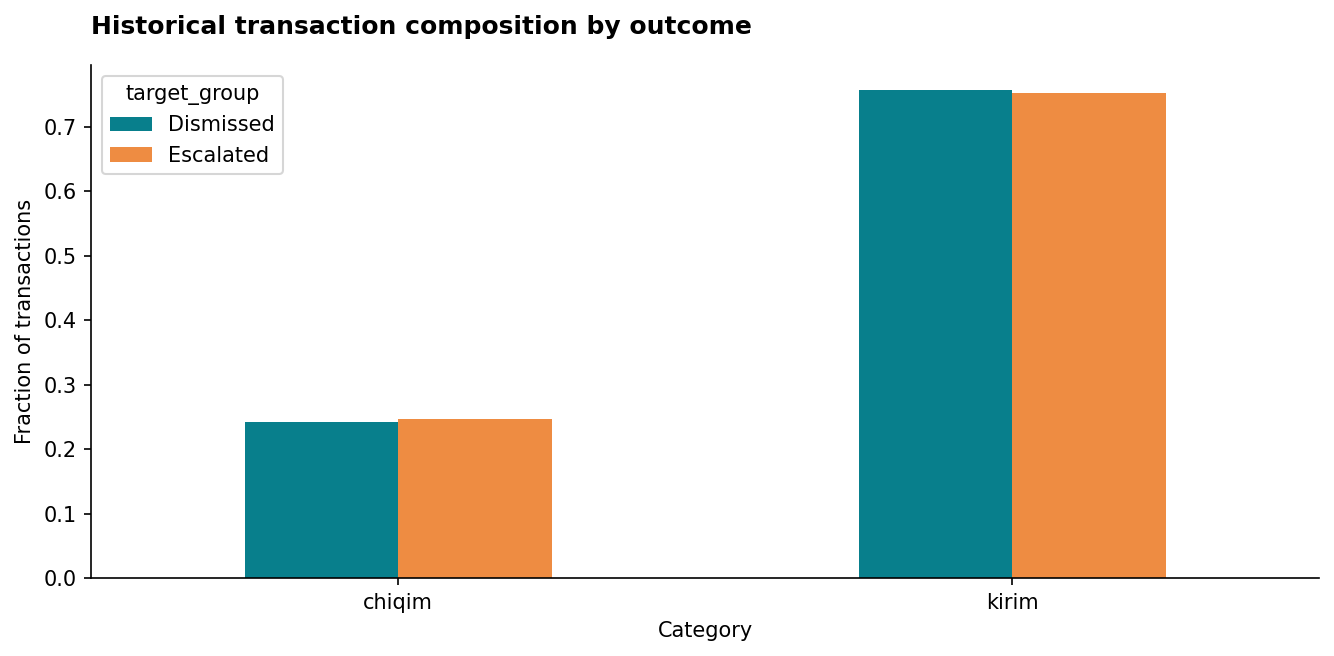

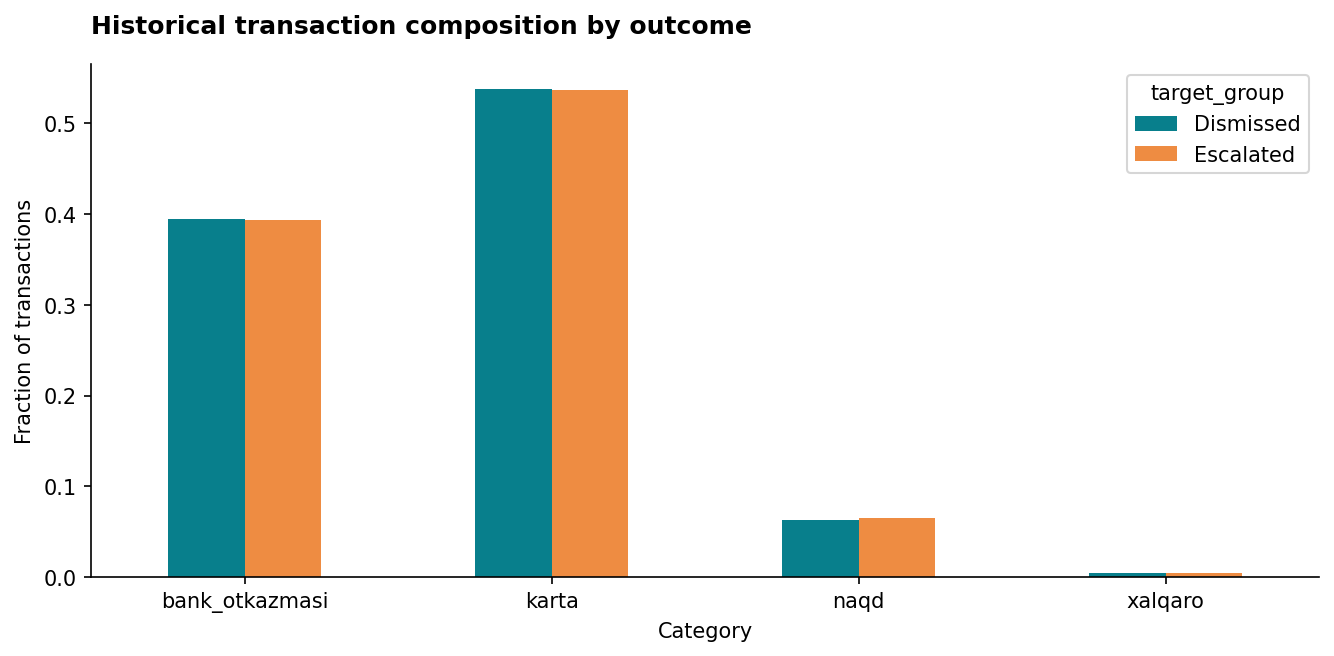

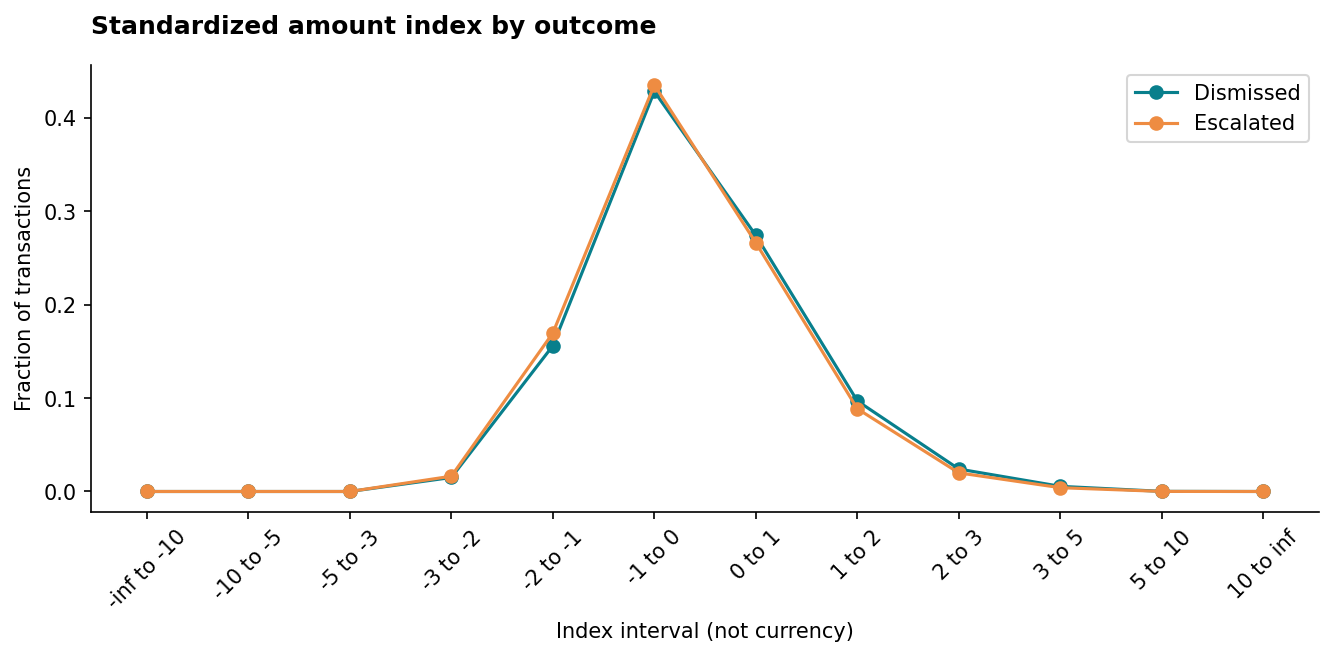

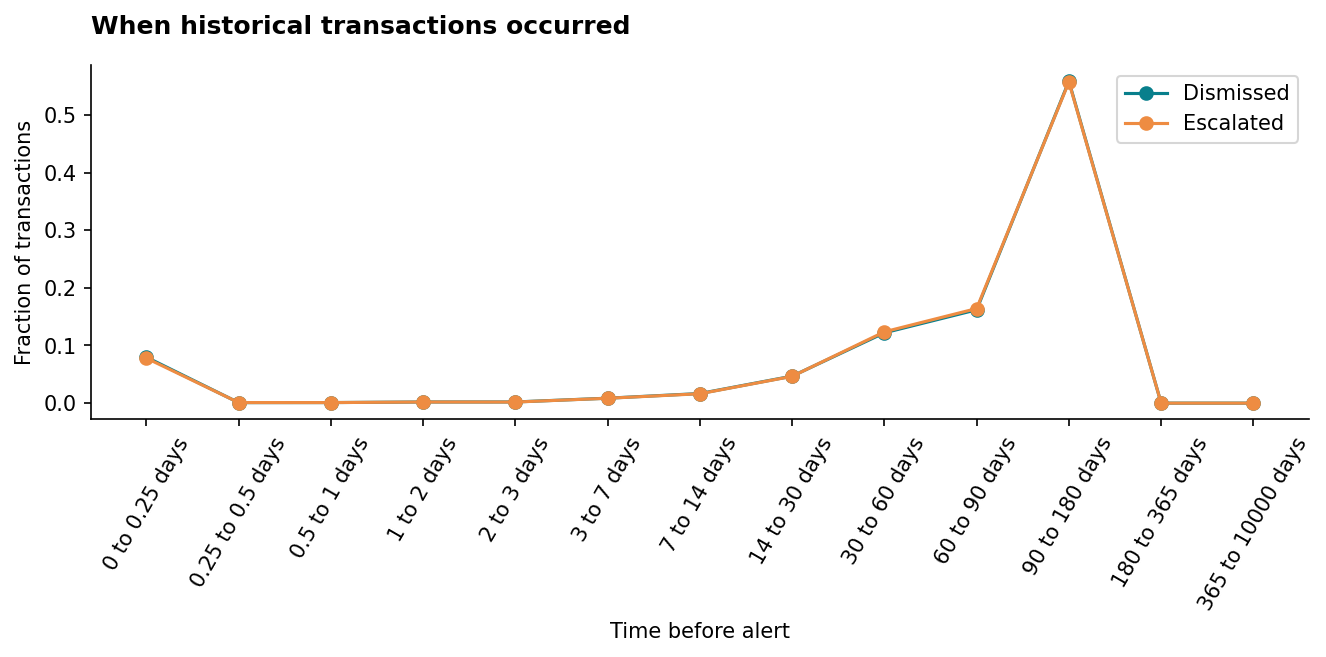

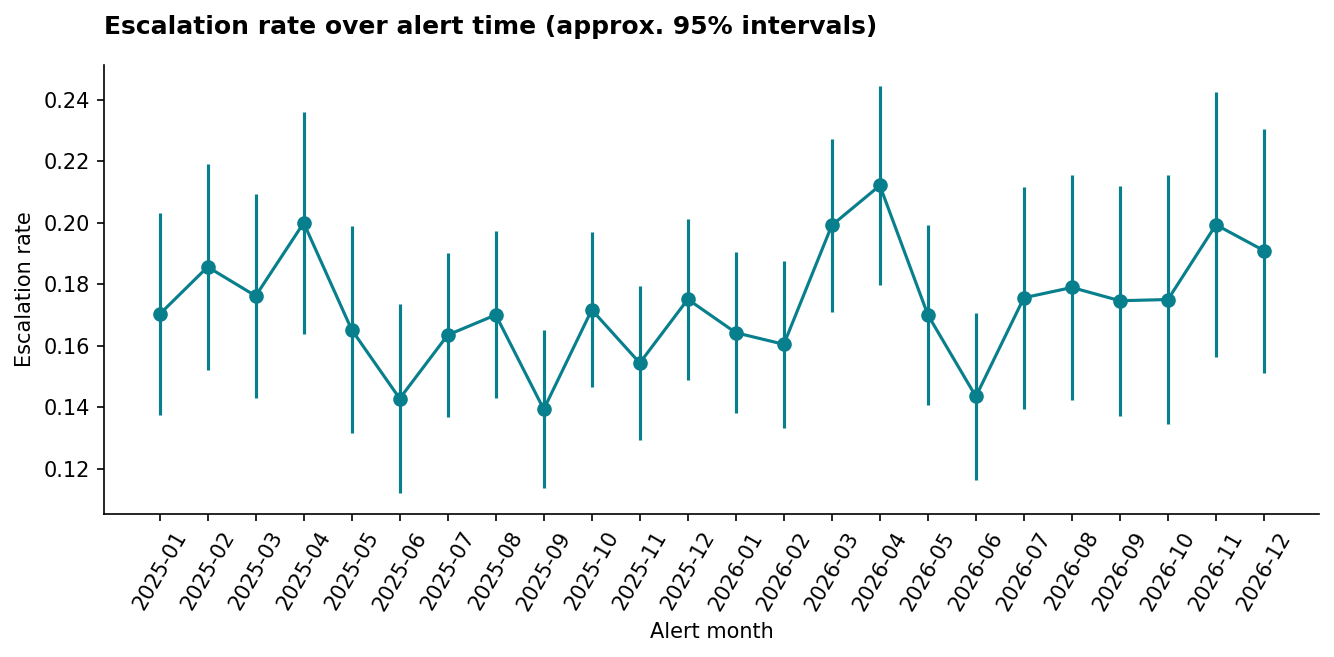

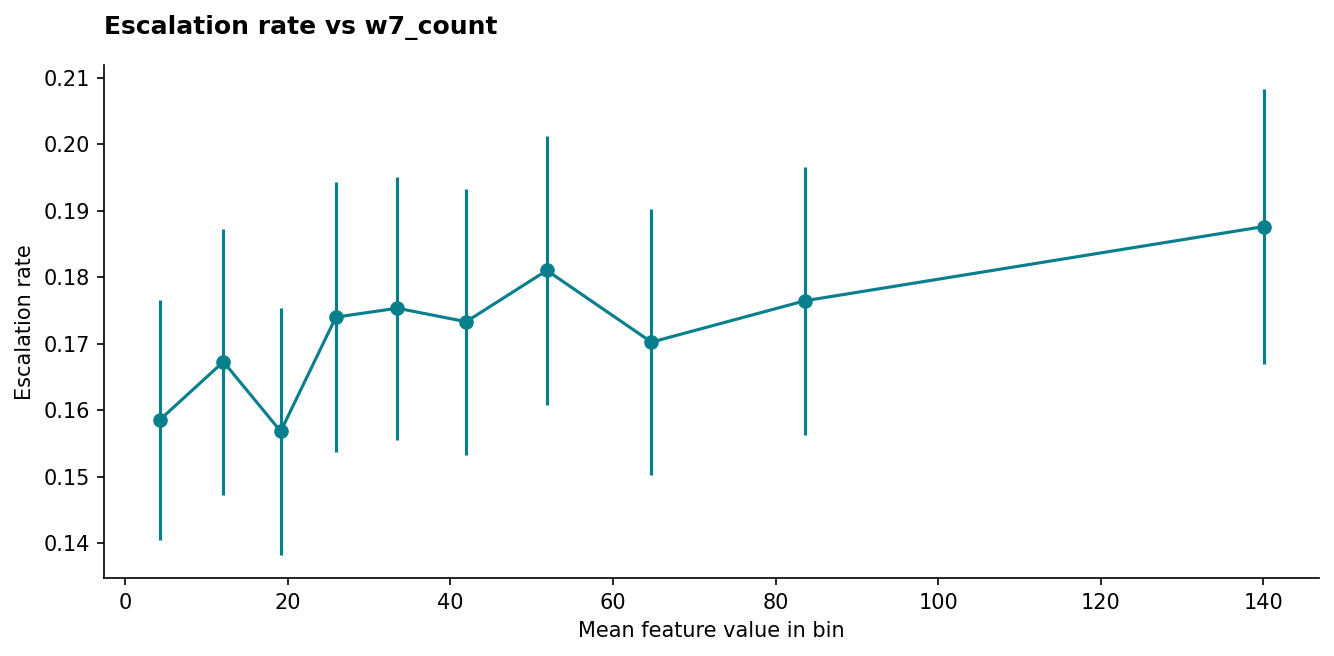

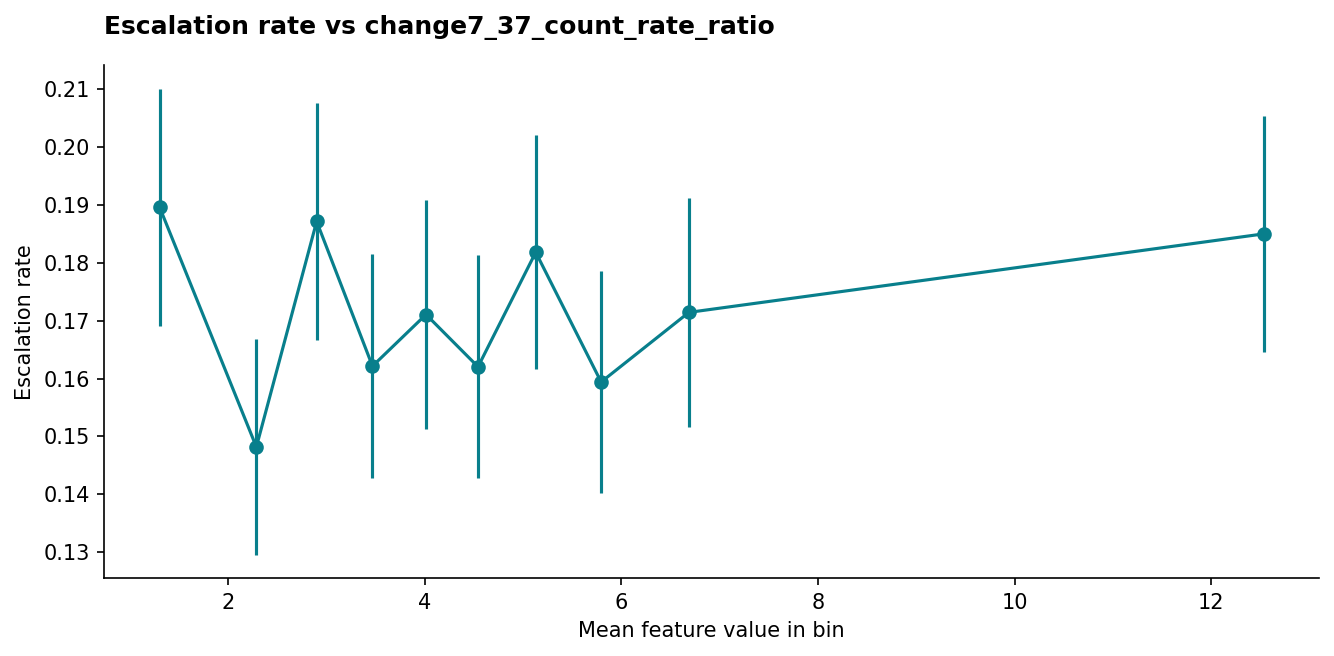

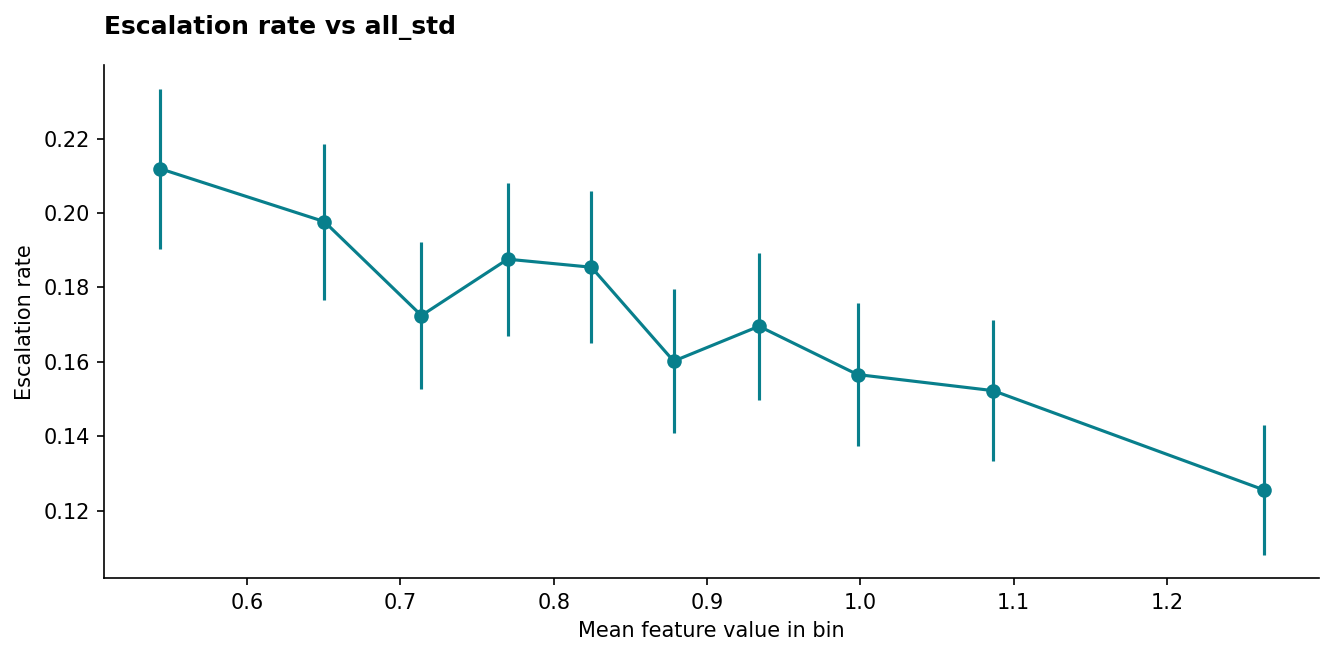

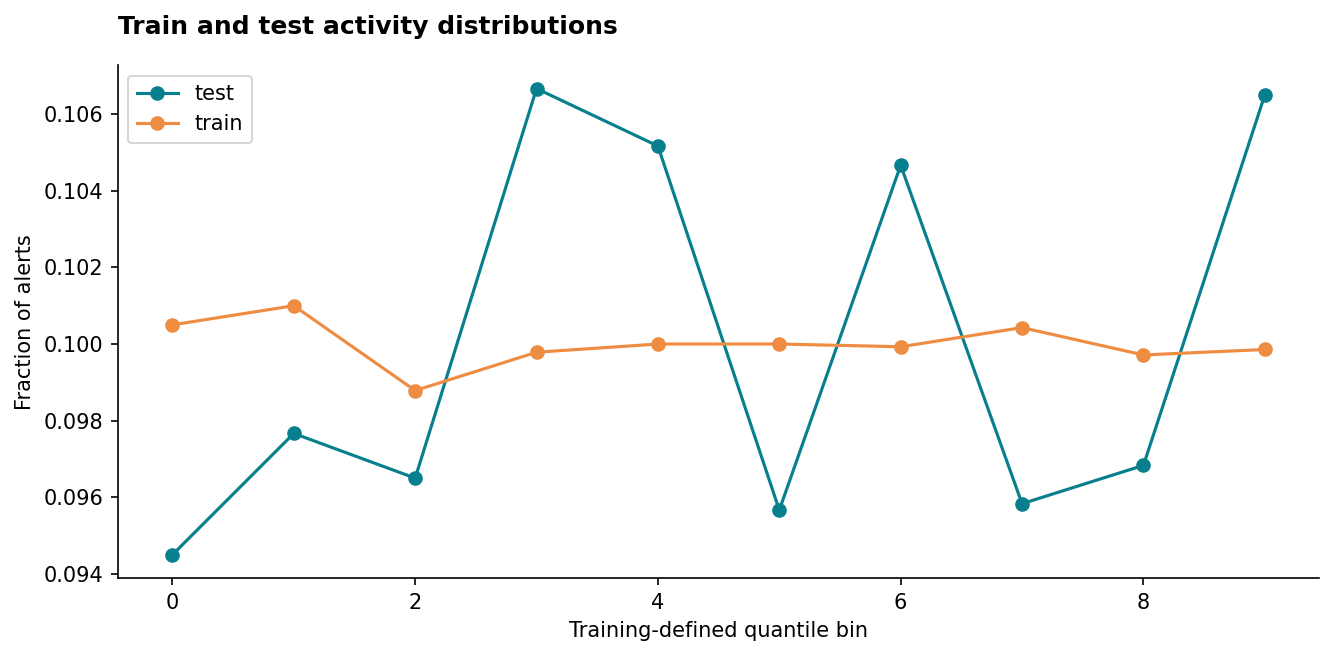

In [5]:
generate_eda()
for name in ['target', 'activity', 'volume', 'direction', 'types', 'amount', 'recency', 'target_time', 'recent_target', 'burst_target', 'volatility_target', 'train_test']:
    display(Image(filename=str(ROOT / 'eda_site' / 'plots' / f'{name}.png'), width=850))

### Interpretations supported by the data

- **Target:** 17.18% of alerts are escalated. Use stratified folds and ROC-AUC rather than accuracy.
- **History volume:** escalated alerts have median 493 transactions versus 455 for dismissed alerts; counts alone remain weak predictors.
- **Calendar volume:** finite history/alert coverage changes monthly totals; this is not evidence of economic seasonality.
- **Composition:** incoming transactions and card/bank transfers dominate. Rare cash/international activity needs both counts and proportions. These plots weight transactions; alert-level features avoid letting long histories dominate the model.
- **Amount behavior:** escalated alerts have slightly lower full-history amount means and volatility. Type-specific contrasts are more useful than a single global amount statistic.
- **Recency:** many transactions cluster shortly before alerts, but median seven-day shares are nearly identical across outcomes (about 8.9%). Do not claim a large burst-related effect based on this dataset.
- **Binned target rates:** intervals are descriptive, and overlapping error bars caution against interpreting small differences. No target-rate bins are used as features.
- **Train/test:** date and activity distributions are similar. This supports, but does not prove, comparable hidden-test behavior.

## 6. Validation strategy
Primary outer splits: five shuffled stratified folds, seed 20260927. Expanding temporal holdouts train only on dates strictly before validation. There is no customer ID for grouped CV. No exact duplicate complete feature rows were detected.

In [6]:
diagnostics = validation_diagnostics()
display(pd.Series(diagnostics))
s = train.set_index('signal_id').loc[X.index]
fold_rows = []
for strategy in ['stratified', 'temporal']:
    for fold, (tr, va) in enumerate(make_splits(s, strategy), start=1):
        fold_rows.append({'strategy': strategy, 'fold': fold, 'training alerts': len(tr), 'validation alerts': len(va),
                          'last training date': str(s.signal_sanasi.iloc[tr].max().date()),
                          'first validation date': str(s.signal_sanasi.iloc[va].min().date())})
display(pd.DataFrame(fold_rows))

{
  "monthly_target_chi2": 32.31122374684344,
  "monthly_target_pvalue": 0.09384209872814407,
  "monthly_target_dof": 23,
  "train_test_date_ks": 0.005976190476190468,
  "train_test_date_ks_pvalue": 0.9980832557054076,
  "adversarial_source_auc": 0.497799988095238,
  "adversarial_fold_auc": [
    0.5000182665523891,
    0.4958555817441612,
    0.497445617231033
  ],
  "duplicate_full_feature_rows_train": 0,
  "duplicate_full_feature_rows_across_splits": 0,
  "interpretation": "Test dates are interspersed with training dates. Use 5-fold stratification for primary model selection, and expanding temporal splits as a robustness check. No customer identifier exists, so repeated-customer dependence cannot be ruled out."
}


monthly_target_chi2                                                                  32.311224
monthly_target_pvalue                                                                 0.093842
monthly_target_dof                                                                          23
train_test_date_ks                                                                    0.005976
train_test_date_ks_pvalue                                                             0.998083
adversarial_source_auc                                                                  0.4978
adversarial_fold_auc                         [0.5000182665523891, 0.4958555817441612, 0.497...
duplicate_full_feature_rows_train                                                            0
duplicate_full_feature_rows_across_splits                                                    0
interpretation                               Test dates are interspersed with training date...
dtype: object

,strategy,fold,training alerts,validation alerts,last training date,first validation date
0,stratified,1,11200,2800,2026-12-31,2025-01-01
1,stratified,2,11200,2800,2026-12-31,2025-01-01
2,stratified,3,11200,2800,2026-12-31,2025-01-01
3,stratified,4,11200,2800,2026-12-31,2025-01-01
4,stratified,5,11200,2800,2026-12-31,2025-01-01
5,temporal,1,7588,2638,2025-12-31,2026-01-01
6,temporal,2,10226,2013,2026-04-19,2026-04-20
7,temporal,3,12239,1761,2026-08-07,2026-08-08


Exploratory boosted models use outer validation for early stopping. For the frozen final recipe, a separate 20% stratified **inner** split chooses boosting rounds; each outer training fold is then refitted before predicting its untouched outer fold. This controls stopping optimism but is **not a fully nested re-run of all model/feature selection**. Every model stores OOF probabilities.

## 7. Baseline and feature ablations
The same LightGBM configuration measures the incremental feature groups. Constant/duplicate removal is fold-local. Poorer ablations are retained in the experiment record.

In [7]:
loaded = (X, X_test, groups, s)
ablation_names = ['lgb_baseline', 'lgb_recent', 'lgb_direction', 'lgb_types', 'lgb_change', 'lgb_sequence', 'lgb_full']
for name in ablation_names:
    run_experiment(name, force=RETRAIN_CORE_EXPERIMENTS, loaded=loaded)
display(update_results().query("experiment in @ablation_names and validation == 'stratified'")
        [['experiment', 'features', 'auc_mean', 'auc_std', 'auc_oof']])

C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_baseline stratified fold 1/5: AUC=0.596687, iterations=47, features=34, elapsed=1.0s


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_baseline stratified fold 2/5: AUC=0.584885, iterations=7, features=34, elapsed=1.8s


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_baseline stratified fold 3/5: AUC=0.613546, iterations=3, features=34, elapsed=2.7s


... (68 outputs left out)

C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_full stratified fold 5/5: AUC=0.658673, iterations=118, features=833, elapsed=40.1s


FINISHED lgb_full stratified: 0.634516 +/- 0.013550; pooled OOF 0.634322


,experiment,features,auc_mean,auc_std,auc_oof
24,lgb_types,types,0.636088,0.012159,0.633200
20,lgb_full,full,0.634516,0.013550,0.634322
23,lgb_sequence,sequence,0.633402,0.012285,0.631048
11,lgb_change,change,0.631859,0.013680,0.630152
10,lgb_baseline,baseline,0.605589,0.015326,0.598761
18,lgb_direction,direction,0.602946,0.016237,0.592653
21,lgb_recent,recent,0.600206,0.015187,0.596450


## 8. Stronger model comparisons
The core comparison contrasts refined LightGBM, compact CatBoost, shallow XGBoost, and regularized logistic regression. The full report also records histogram boosting, ExtraTrees, spline models, native CatBoost categories, depth/leaves/regularization tuning, and fold-local feature selection.

In [8]:
core_names = ['lgb_contrasts', 'cat_compact', 'xgb_compact', 'logistic_compact']
for name in core_names:
    run_experiment(name, force=RETRAIN_CORE_EXPERIMENTS, loaded=loaded)
display(update_results().query("experiment in @core_names and validation == 'stratified'")
        [['experiment', 'model', 'auc_mean', 'auc_std', 'auc_oof', 'fold_auc']])

C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_contrasts stratified fold 1/5: AUC=0.644953, iterations=167, features=832, elapsed=8.6s


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_contrasts stratified fold 2/5: AUC=0.634462, iterations=205, features=831, elapsed=17.7s


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_contrasts stratified fold 3/5: AUC=0.658649, iterations=76, features=831, elapsed=24.0s


... (20 outputs left out)

logistic_compact stratified fold 4/5: AUC=0.628754, iterations=0, features=210, elapsed=4.2s


logistic_compact stratified fold 5/5: AUC=0.652657, iterations=0, features=210, elapsed=5.2s


FINISHED logistic_compact stratified: 0.635252 +/- 0.009090; pooled OOF 0.635176


,experiment,model,auc_mean,auc_std,auc_oof,fold_auc
16,lgb_contrasts,lgb,0.654022,0.014618,0.652407,0.644953; 0.634462; 0.658649; 0.653895; 0.678149
3,cat_compact,cat,0.651829,0.013179,0.651110,0.641720; 0.634305; 0.652484; 0.658429; 0.672205
30,xgb_compact,xgb,0.651324,0.014890,0.648970,0.643101; 0.628511; 0.657343; 0.654579; 0.673089
25,logistic_compact,logistic,0.635252,0.009090,0.635176,0.635550; 0.628052; 0.631245; 0.628754; 0.652657


## 9. Ensemble assessment and stricter validation
Blend weights are coarse (25/50/75%), not finely optimized. The frozen 50/50 LightGBM/CatBoost recipe lies on a broad performance plateau. Its gain is small; do not claim statistical certainty.

In [9]:
blend_table = assess_blends(core_names)
display(blend_table[['blend', 'auc_mean', 'auc_std', 'auc_oof']])
selection = json.loads((ROOT / 'solution' / 'selection.json').read_text())
for strategy in ['nested', 'temporal']:
    for name, config in selection['configs'].items():
        run_experiment(name, config=config, strategy=strategy, force=RETRAIN_CORE_EXPERIMENTS, loaded=loaded)
display(update_results().query("validation != 'stratified'")[['experiment', 'validation', 'auc_mean', 'auc_std', 'auc_oof']])

                                   blend                                           weights  auc_mean  auc_std  auc_oof                                                                                             fold_auc
       lgb_contrasts:0.5+cat_compact:0.5        {"lgb_contrasts": 0.5, "cat_compact": 0.5}  0.654975 0.014085 0.654104  [0.6452661239207165, 0.6357963097937225, 0.6583685885108912, 0.657890749740685, 0.6775538599600696]
     lgb_contrasts:0.75+cat_compact:0.25      {"lgb_contrasts": 0.75, "cat_compact": 0.25}  0.654965 0.014549 0.653869 [0.6455377658482445, 0.6352655770508293, 0.6589629733226112, 0.6563532385007159, 0.6787031832309971]
lgb_contrasts:0.75+logistic_compact:0.25 {"lgb_contrasts": 0.75, "logistic_compact": 0.25}  0.654626 0.013491 0.653517 [0.6452661239207165, 0.6372020343559801, 0.6594551562210036, 0.6543235443623543, 0.6768841684753715]
     lgb_contrasts:0.25+cat_compact:0.75      {"lgb_contrasts": 0.25, "cat_compact": 0.75}  0.654028 0.013540 0.653354  

,blend,auc_mean,auc_std,auc_oof
5,lgb_contrasts:0.5+cat_compact:0.5,0.654975,0.014085,0.654104
6,lgb_contrasts:0.75+cat_compact:0.25,0.654965,0.014549,0.653869
12,lgb_contrasts:0.75+logistic_compact:0.25,0.654626,0.013491,0.653517
4,lgb_contrasts:0.25+cat_compact:0.75,0.654028,0.013540,0.653354
9,lgb_contrasts:0.75+xgb_compact:0.25,0.654434,0.014623,0.652938
8,lgb_contrasts:0.5+xgb_compact:0.5,0.654115,0.014751,0.652445
0,lgb_contrasts,0.654022,0.014618,0.652407
7,lgb_contrasts:0.25+xgb_compact:0.75,0.653116,0.014710,0.651188
1,cat_compact,0.651829,0.013179,0.651110
11,lgb_contrasts:0.5+logistic_compact:0.5,0.651203,0.011149,0.650649


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_contrasts nested fold 1/5: AUC=0.637983, iterations=63, features=832, elapsed=8.1s


C:\Users\PRESTIGE\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lgb_contrasts nested fold 2/5: AUC=0.631652, iterations=80, features=831, elapsed=17.3s


... (21 outputs left out)

cat_compact temporal fold 2/3: AUC=0.656155, iterations=202, features=210, elapsed=7.2s


cat_compact temporal fold 3/3: AUC=0.689098, iterations=134, features=210, elapsed=11.2s


FINISHED cat_compact temporal: 0.659786 +/- 0.022597; pooled OOF 0.660009


,experiment,validation,auc_mean,auc_std,auc_oof
15,lgb_contrasts,nested,0.650748,0.015468,0.648990
2,cat_compact,nested,0.647492,0.013283,0.646003
29,xgb_compact,nested,0.645541,0.017535,0.645892
17,lgb_contrasts,temporal,0.659913,0.032066,0.657065
4,cat_compact,temporal,0.659786,0.022597,0.660009
31,xgb_compact,temporal,0.657308,0.024146,0.653943


## 10. Final all-data fitting and feature importance
Use the frozen blend weights and median inner-selected iteration counts. The final models are refitted on all training alerts. Importance is descriptive; correlated predictors can share or substitute importance.

In [10]:
submission, final_summary = finalize(team_id=TEAM_ID)
display(pd.Series({k: final_summary[k] for k in ['description', 'validation_strategy', 'auc_mean', 'auc_std', 'auc_oof', 'oof_auc_bootstrap_interval_95']}))
importance = pd.read_csv(ARTIFACTS / 'final_importance.csv')
display(importance.head(25))
ax = importance.head(20).iloc[::-1].plot.barh(x='feature', y='importance', legend=False, figsize=(10, 7), title='Final model feature importance')
display(ax.figure)

Cached lgb_contrasts nested: 0.650748


Cached lgb_contrasts stratified: 0.654022


Cached lgb_contrasts temporal: 0.659913


Full-data refit: lgb_contrasts, weight=0.5, iterations=70, features=832


Cached cat_compact nested: 0.647492


Cached cat_compact stratified: 0.651829


... (3 outputs left out)

Validated submission saved to D:\Data science\hakathon\wiut_task\team_SUBMIT_READY.csv


description                      50% LightGBM with type contrasts + 50% compact...
validation_strategy                                                         nested
auc_mean                                                                   0.65133
auc_std                                                                    0.01479
auc_oof                                                                   0.650206
oof_auc_bootstrap_interval_95             [0.6374122690707426, 0.6629795318255862]
dtype: object

,feature,importance
0,all_karta_to_bank_otkazmasi_std,0.101154
1,all_bank_otkazmasi_minus_naqd_mean_z,0.064444
2,type_karta_min,0.054175
3,all_karta_minus_bank_otkazmasi_mean_z,0.050036
4,all_min,0.038306
5,all_bank_otkazmasi_minus_naqd_mean,0.035965
6,type_karta_chiqim_min,0.022424
7,type_bank_otkazmasi_min,0.022251
8,all_naqd_direction_amount_difference,0.022051
9,type_bank_otkazmasi_kirim_min,0.021989


<Figure size 1000x700 with 1 Axes>

## 11. Test prediction and submission validation
Predictions are continuous probabilities. Validate the actual serialized CSV, exact column order, sample ID order, complete coverage, unique IDs, finite values, range, and nonzero variance.

In [11]:
output_path = ROOT / f'team_{TEAM_ID}.csv'
saved = pd.read_csv(output_path)
checks = validate_submission(saved, test, sample)
display(pd.Series(checks))
display(saved.head())
print('Final submission:', output_path)

rows                                                                 6000
columns                                           [signal_id, ehtimollik]
unique_ids                                                           6000
matches_sample_order                                                 True
finite                                                               True
range_valid                                                          True
prediction_summary      {'count': 6000.0, 'mean': 0.17734688285425243,...
dtype: object

,signal_id,ehtimollik
0,SG_000001,0.117408
1,SG_000007,0.147474
2,SG_000009,0.110318
3,SG_000010,0.111994
4,SG_000011,0.146054


Final submission: D:\Data science\hakathon\wiut_task\team_SUBMIT_READY.csv


## 12. Integrity checks and report export

In [12]:
from solution.verify import integrity_checks
integrity_checks()
generate_report()
print('EDA site: python -m streamlit run eda_site/app.py')
print('Raw files unchanged; future-transaction invariance checked.')

{'future_transaction_invariance': True, 'enhanced_future_transaction_invariance': True, 'features_checked': 1065, 'exact_cutoff_inclusion': True, 'signal_row_order_preserved': True, 'no_identifier_or_target_predictors': True, 'source_files_unchanged': True}


README, experiment report, public findings, and environment manifest written.


EDA site: python -m streamlit run eda_site/app.py
Raw files unchanged; future-transaction invariance checked.


## 13. Conclusions

The useful signal is concentrated in type-specific amount distributions and within-alert contrasts. Adding every temporal/sequence feature does not automatically help. A compact CatBoost model complements refined LightGBM slightly.

Read `final_summary` for the **measured** strict five-fold score, exploratory score, and temporal check. The expected strict mean AUC is about **0.6513**; exploratory mean AUC is about **0.6550**. These are local estimates, not a leaderboard result. Fold reuse for model selection, missing customer identifiers, and uncertainty about date-only alert availability remain limitations.

Rename `team_SUBMIT_READY.csv` with your team ID before uploading. The Streamlit site is ready to run locally; public hosting requires your own deployment step.